This notebook plots and saves brain maps of T1w:T2w data and of the corresponding hierarchy in Schaefer100.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.special import erf
from nibabel.freesurfer.io import read_annot
from nilearn import datasets, plotting
from matplotlib.colors import LinearSegmentedColormap
import scienceplots
plt.style.use(['science', 'nature'])

plot_params = {
    "figure.dpi": "600",
    "axes.labelsize": 20,
    "axes.linewidth": 1.5,
    "axes.titlesize": 20,
    "xtick.labelsize": 25,
    "ytick.labelsize": 25,
    "legend.title_fontsize": 30,
    "legend.fontsize": 13,
    "xtick.major.size": 3.5,
    "xtick.major.width": 1.5,
    "xtick.minor.size": 2.5,
    "xtick.minor.width": 1.5,
    "ytick.major.size": 3.5,
    "ytick.major.width": 1.5,
    "ytick.minor.size": 2.5,
    "ytick.minor.width": 1.5,
}
plt.rcParams.update(plot_params)
hier_cmap = LinearSegmentedColormap.from_list(
    "hier_seq",
    ["#f7f7f7", "#cccccc", "#525252"],
    N=256,
)

## T1w:T2w

In [ ]:
t1t2 = pd.read_csv('../../data/processed/schaefer100_t1wt2w.csv')['T1w:T2w'][:100]

annot_path = ('../../data/raw/brain_annotations/Schaefer/fsaverage/'
               'atl-Schaefer2018_space-fsaverage_hemi-L_'
               'desc-100Parcels7Networks_deterministic.annot')
labels, ctab, region_names = read_annot(annot_path)

mapped_t1_t2 = np.zeros_like(labels, dtype=float)
for i in range(len(region_names)):
    if i == 0:
        mapped_t1_t2[labels == i] = np.nan
    else:
        mapped_t1_t2[labels == i] = t1t2[i - 1]
vmin, vmax = np.nanmin(mapped_t1_t2), np.nanmax(mapped_t1_t2)

fs = datasets.fetch_surf_fsaverage('fsaverage')
for view in ['lateral','medial']:
    fig = plt.figure(constrained_layout=True, figsize=(6,6))
    ax = fig.add_subplot(1,1,1, projection='3d')
    plotting.plot_surf_stat_map(
        fs.infl_left, mapped_t1_t2, fs.sulc_left,
        hemi='left', view=view, cmap=hier_cmap,
        colorbar=True, symmetric_cbar=False,
        vmin=vmin, vmax=vmax,
        axes=ax, figure=fig, engine='matplotlib', avg_method='median'
    )
    ax.set_axis_off()
    for ext in ['pdf']:
        dpi = 1200 if ext in ['png'] else None
        fig.savefig(f'../results/t1t2_and_hierarchy_schaefer100/fig1_t1t2_{view}.{ext}', dpi=dpi, transparent=True)
    plt.close()

[get_dataset_dir] Dataset found in /home/rad216/nilearn_data/fsaverage


KeyboardInterrupt: 

## Hierarchy 

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from nibabel.freesurfer.io import read_annot
from nilearn import datasets, plotting


h_vals = pd.read_csv('../../data/processed/schaefer100_LH_hierarchy.csv')['Hierarchy_val']

annot_path = ('../../data/raw/brain_annotations/Schaefer/fsaverage/'
               'atl-Schaefer2018_space-fsaverage_hemi-L_'
               'desc-100Parcels7Networks_deterministic.annot')
labels, ctab, region_names = read_annot(annot_path)

mapped_hierarchy = np.full(labels.shape, np.nan)
for i in range(len(region_names)):
    if i == 0:
        mapped_hierarchy[labels == i] = np.nan
    else:
        mapped_hierarchy[labels == i] = h_vals[i - 1]
vmin, vmax = np.nanmin(mapped_hierarchy), np.nanmax(mapped_hierarchy)

fs = datasets.fetch_surf_fsaverage('fsaverage')
for view in ['lateral','medial']:
    fig = plt.figure(constrained_layout=True, figsize=(6,6))
    ax = fig.add_subplot(1,1,1, projection='3d')
    plotting.plot_surf_stat_map(
        fs.infl_left, mapped_hierarchy, fs.sulc_left,
        hemi='left', view=view,
        cmap=hier_cmap, colorbar=True,
        symmetric_cbar=False,
        vmin=vmin, vmax=vmax,
        axes=ax, figure=fig,
        engine='matplotlib', avg_method='median'
    )
    for ext in ['pdf']:
        dpi = 1200 if ext in ['png'] else None
        fig.savefig(f'../results/t1t2_and_hierarchy_schaefer100/fig1_hierarchy_{view}.{ext}', dpi=dpi, transparent=True)
    plt.close()

[get_dataset_dir] Dataset found in /home/rad216/nilearn_data/fsaverage


: 

## Hierarchy by Yeo functional network

Group the Schaefer100 (LH) parcels into their 7 Yeo networks and summarise the hierarchy per network.

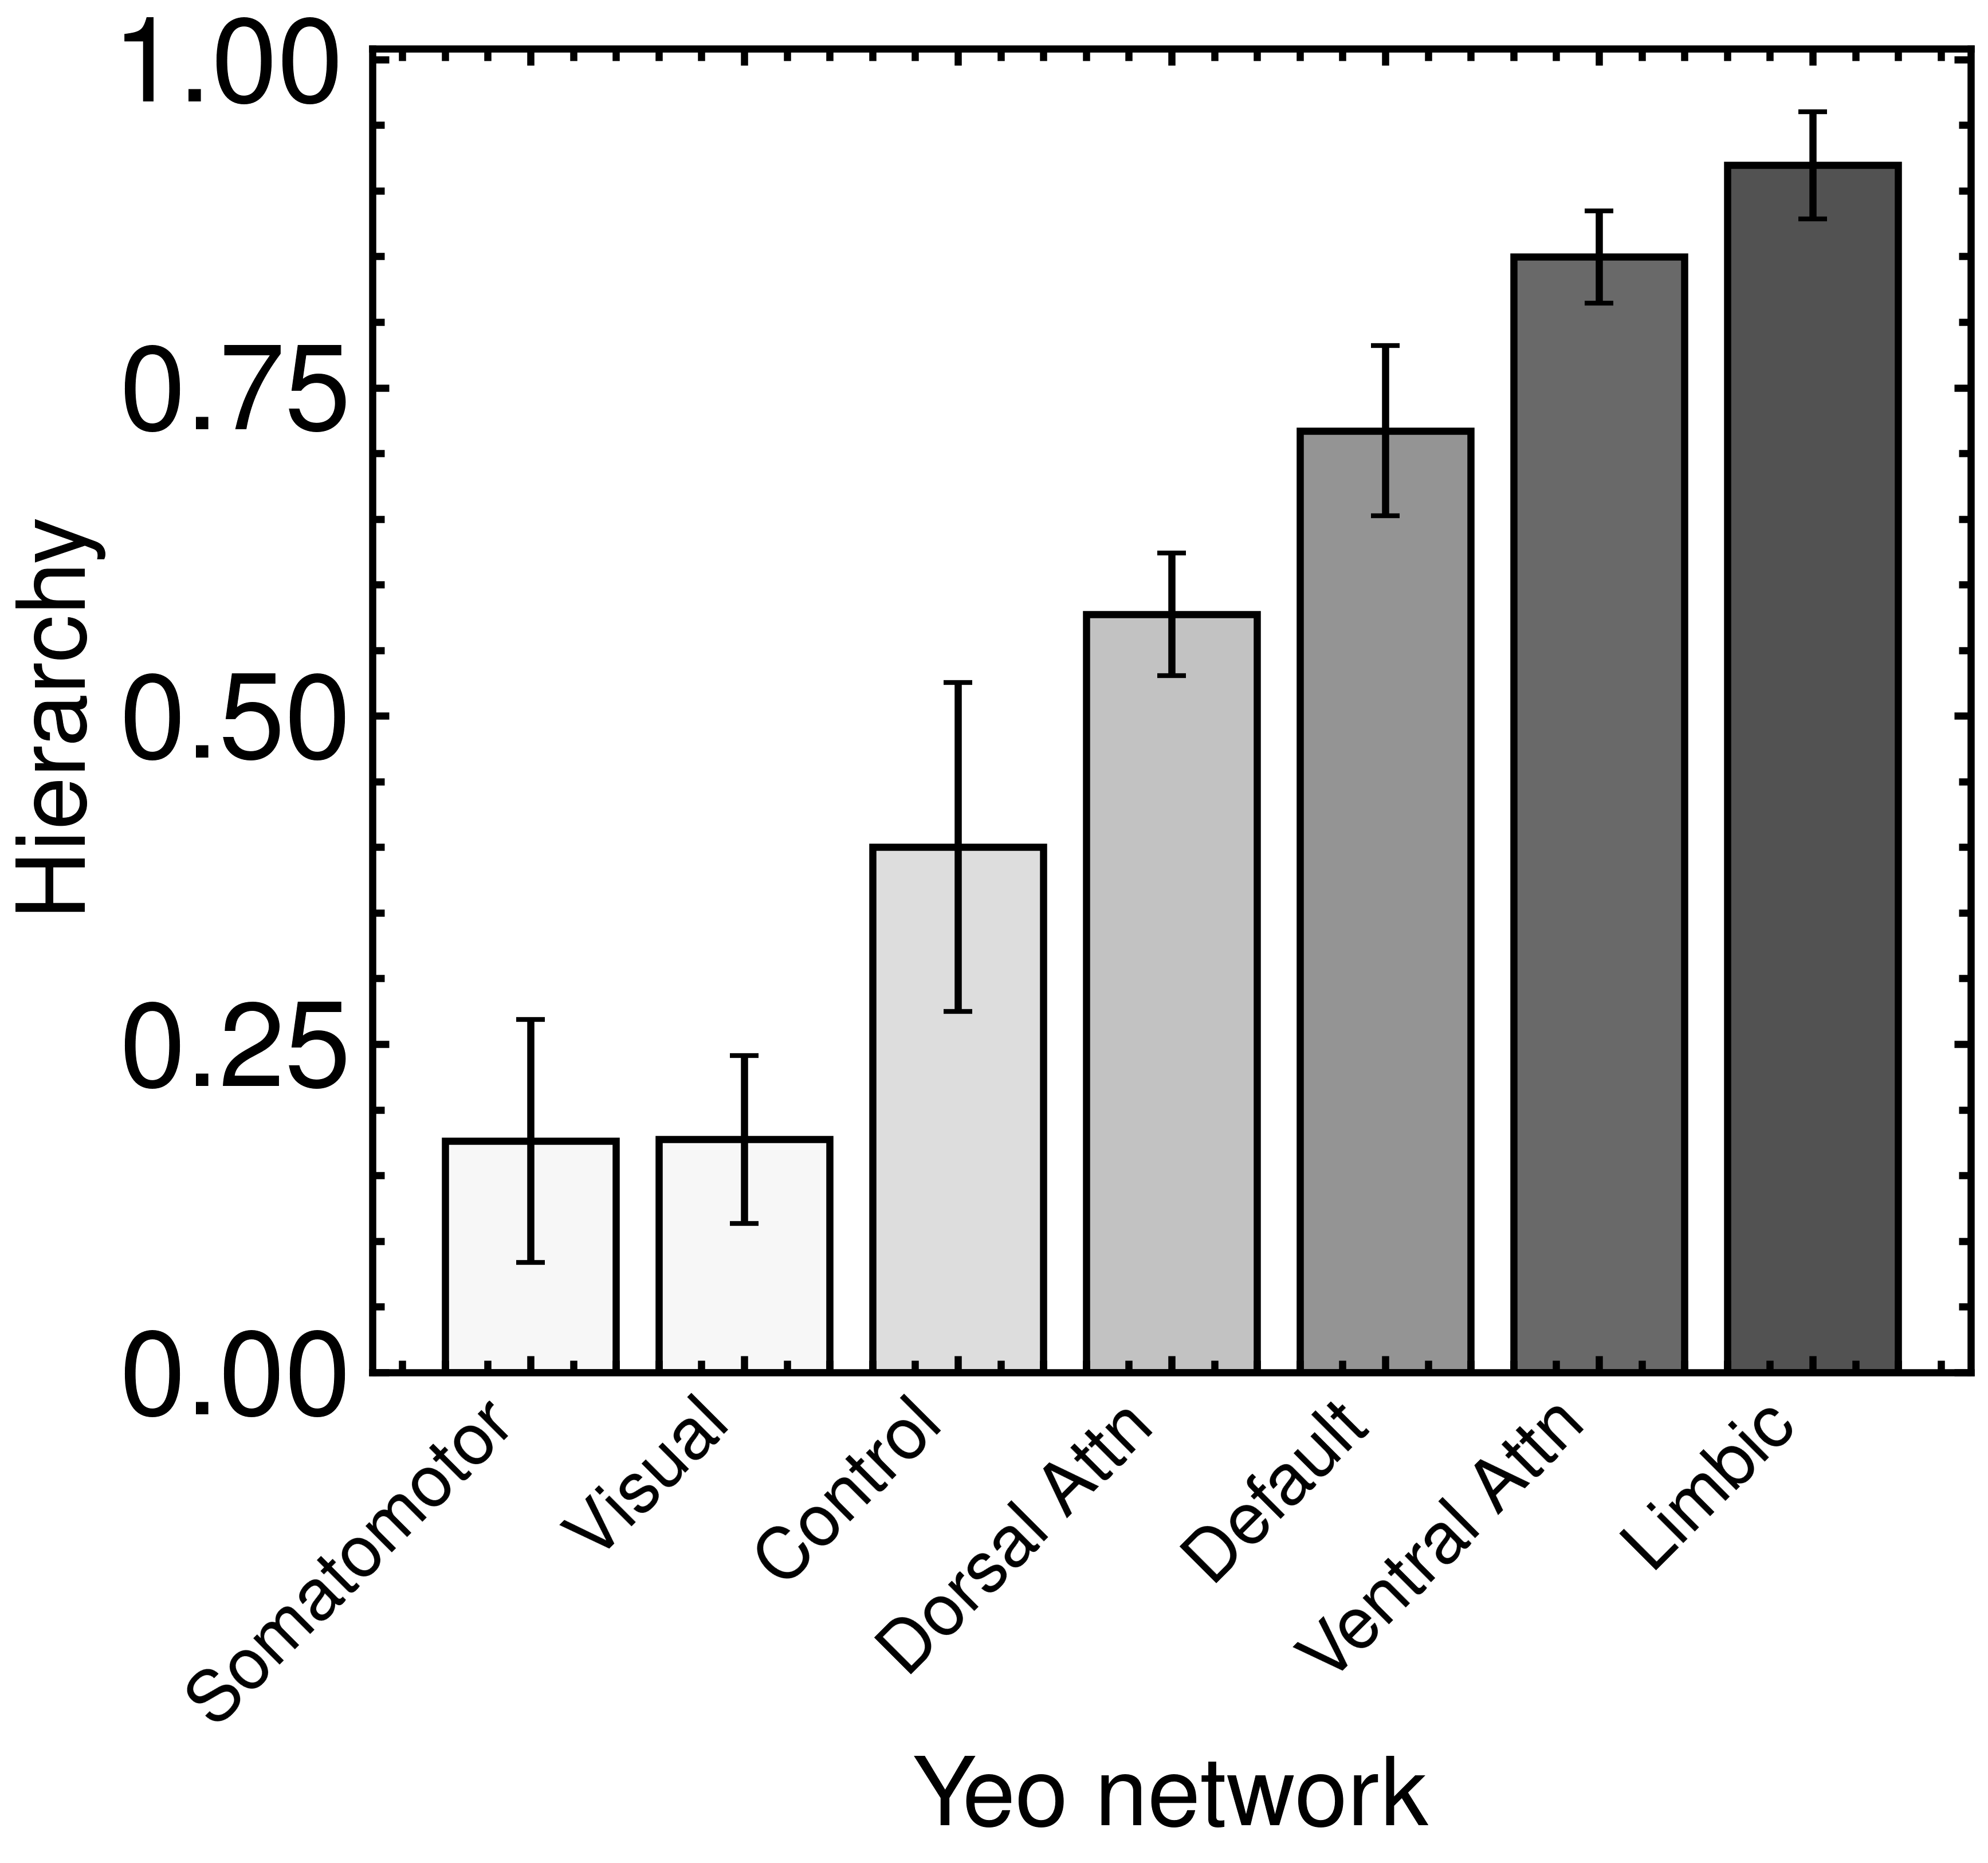

,mean,sem
network,,
SomMot,0.176174,0.092421
Vis,0.177396,0.064041
Cont,0.400081,0.125330
DorsAttn,0.577263,0.046668
Default,0.717265,0.064673
SalVentAttn,0.849548,0.035114
Limbic,0.919401,0.040849


In [3]:
# Hierarchy value per parcel and its Yeo network label (both files are LH, aligned by row)
h_vals = pd.read_csv('../../data/processed/schaefer100_LH_hierarchy.csv')['Hierarchy_val']
area_names = pd.read_csv('../../data/processed/schaefer100_LH_area_names.csv')['Area_name']

# The Yeo network is the 3rd token of e.g. "7Networks_LH_Vis_1"
network = area_names.str.split('_').str[2]

net_df = pd.DataFrame({'network': network.values, 'hierarchy': h_vals.values})

# Readable labels for the 7 Yeo networks
net_labels = {
    'Vis': 'Visual',
    'SomMot': 'Somatomotor',
    'DorsAttn': 'Dorsal Attn',
    'SalVentAttn': 'Ventral Attn',
    'Limbic': 'Limbic',
    'Cont': 'Control',
    'Default': 'Default',
}

# Mean +/- SEM hierarchy per network, ordered low -> high (matches the light -> dark colormap)
summary = (net_df.groupby('network')['hierarchy']
           .agg(['mean', 'sem'])
           .reindex(net_labels.keys())
           .sort_values('mean'))

# Colour each bar by its mean hierarchy using the same sequential colormap as the brain maps
norm = plt.Normalize(summary['mean'].min(), summary['mean'].max())
colors = hier_cmap(norm(summary['mean'].values))

fig, ax = plt.subplots(figsize=(6, 5))
x = np.arange(len(summary))
ax.bar(x, summary['mean'], yerr=summary['sem'],
       color=colors, edgecolor='black', linewidth=1.5,
       error_kw=dict(ecolor='black', elinewidth=1.5, capsize=3))
ax.set_xticks(x)
ax.set_xticklabels([net_labels[n] for n in summary.index],
                   rotation=45, ha='right', fontsize=15)
ax.set_ylabel('Hierarchy')
ax.set_xlabel('Yeo network')

for ext in ['pdf']:
    dpi = 1200 if ext in ['png'] else None
    fig.savefig(f'../results/t1t2_and_hierarchy_schaefer100/fig1_hierarchy_by_network.{ext}',
                dpi=dpi, transparent=True, bbox_inches='tight')
plt.show()

summary

## Hierarchy by Yeo functional network (Schaefer200)

Same summary as above, using the Schaefer200 (LH) parcellation.

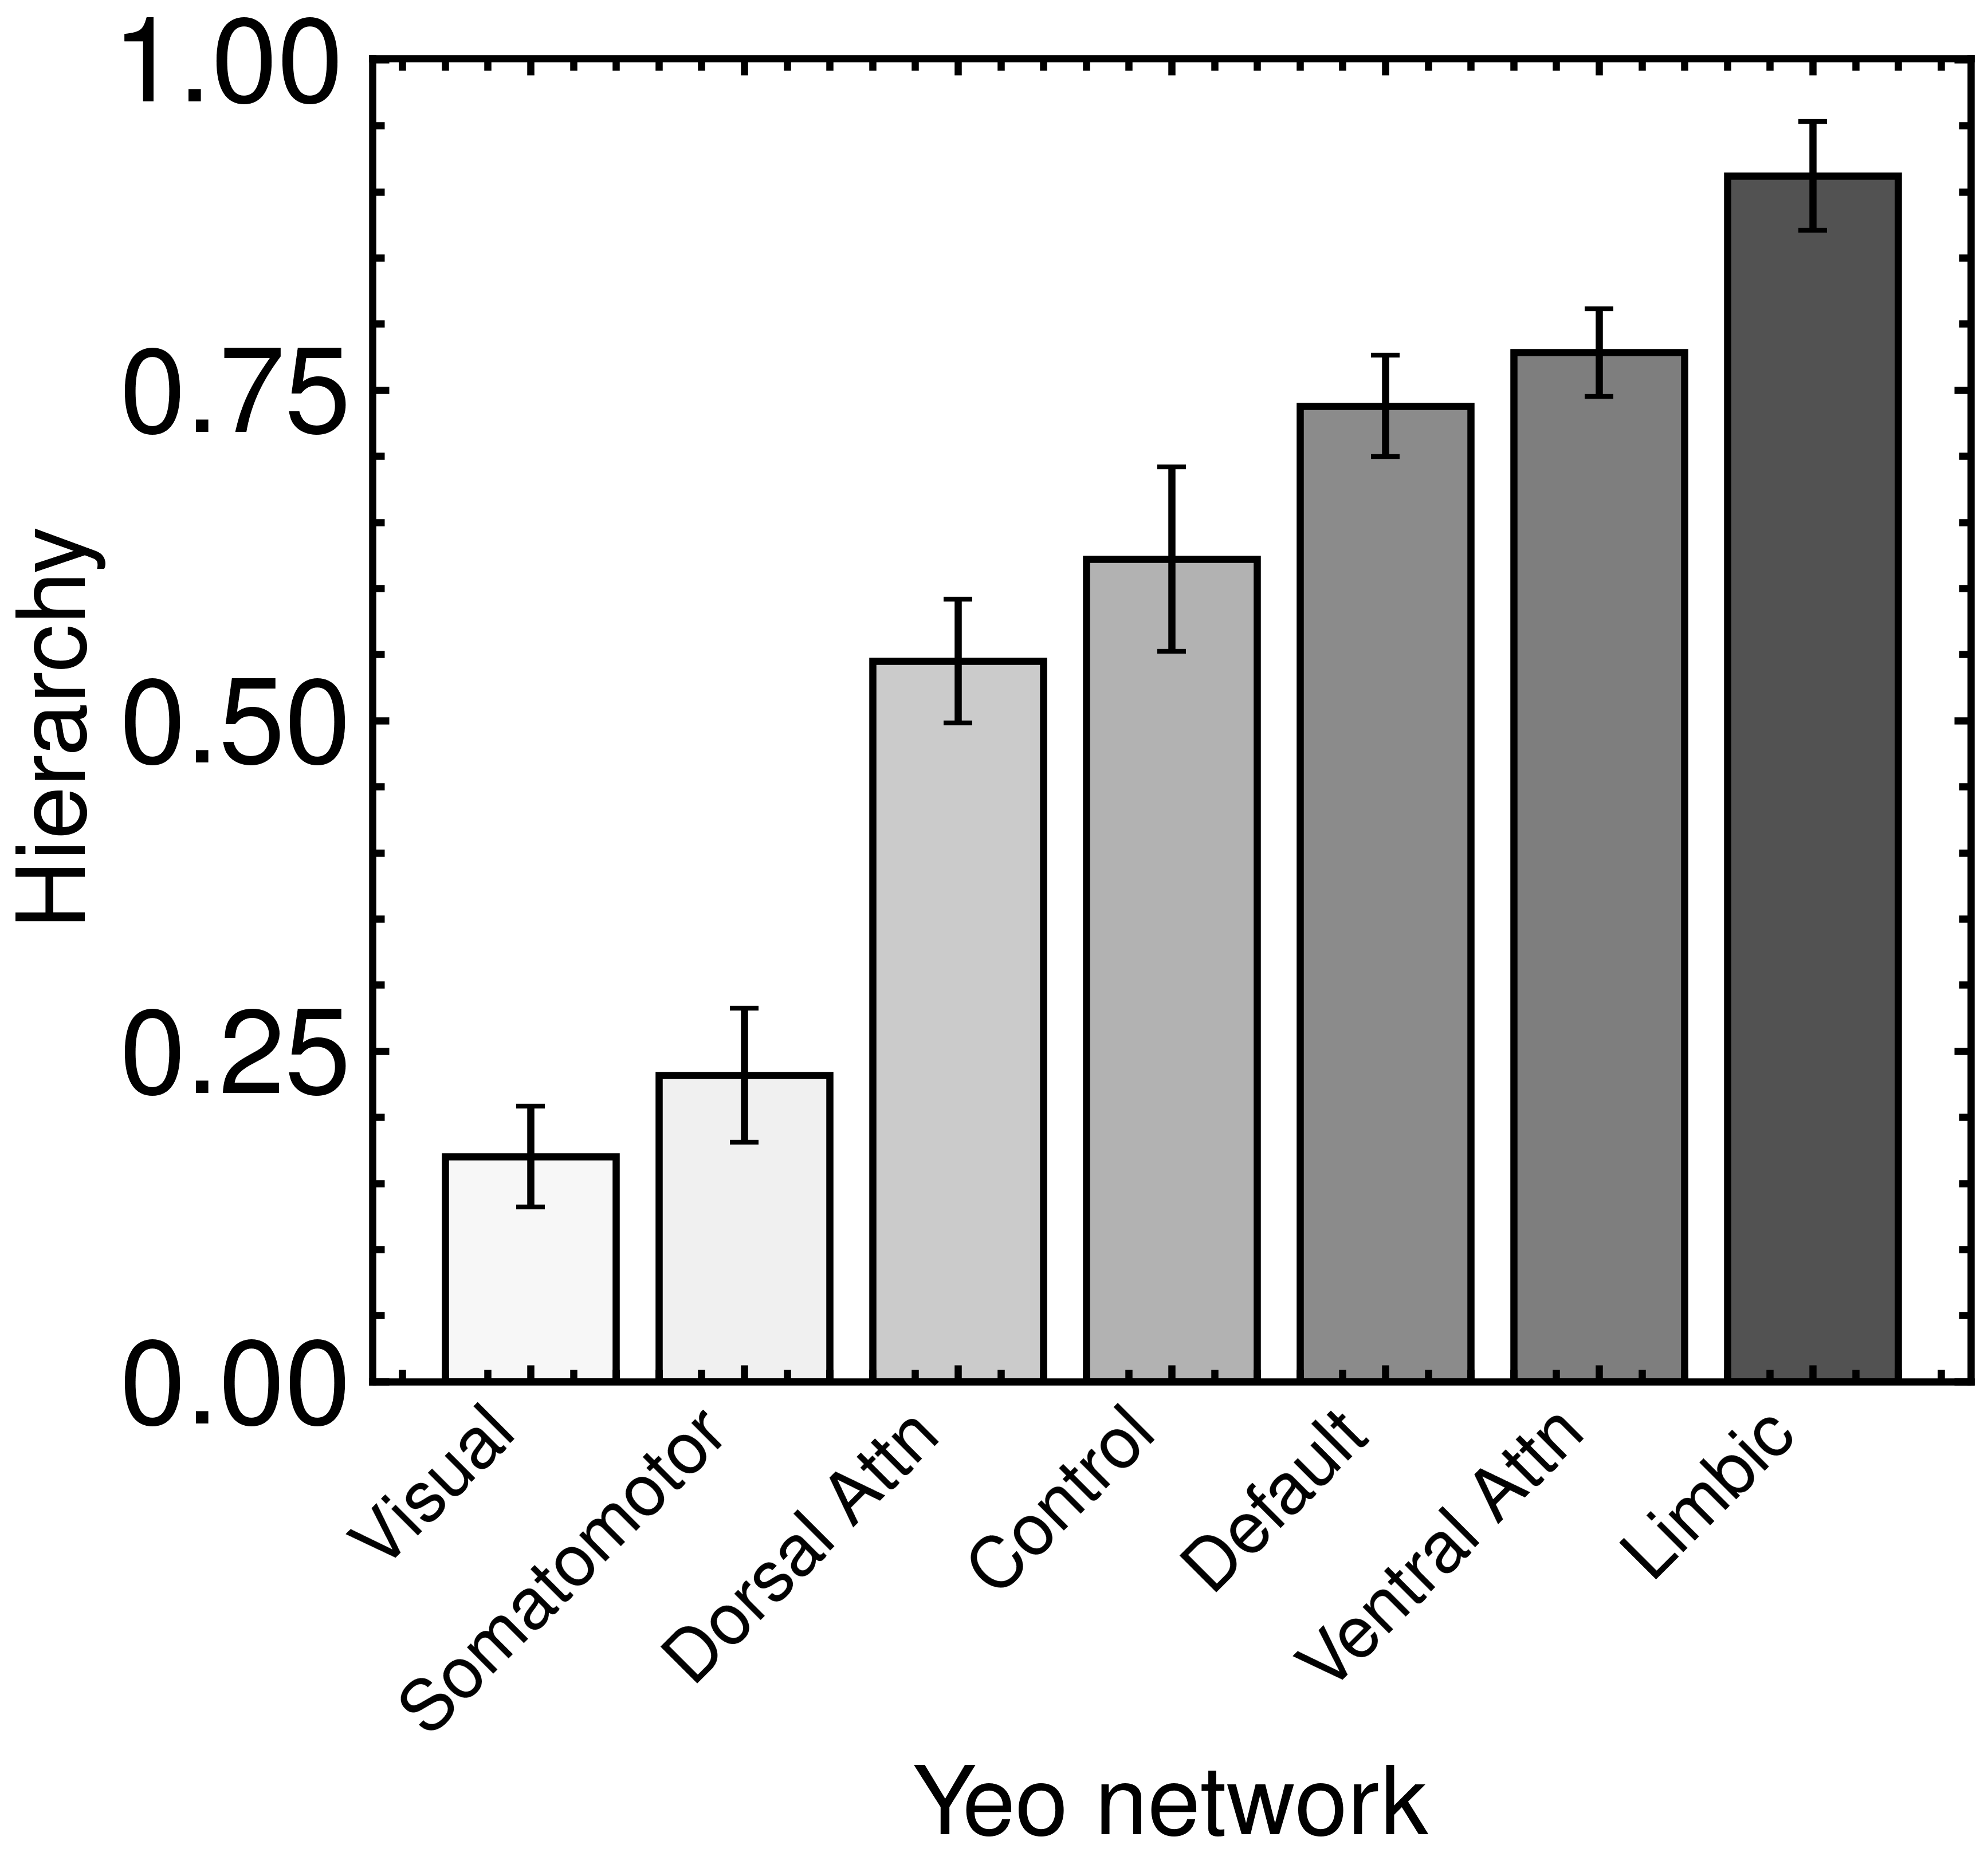

,mean,sem
network,,
Vis,0.170306,0.038171
SomMot,0.231647,0.050590
DorsAttn,0.544821,0.046757
Cont,0.622167,0.069619
Default,0.737962,0.038377
SalVentAttn,0.778426,0.033208
Limbic,0.911972,0.041253


In [ ]:
# Hierarchy value per parcel and its Yeo network label (both files are LH, aligned by row)
h_vals_200 = pd.read_csv('../../data/processed/schaefer200_LH_hierarchy.csv')['Hierarchy_val']
area_names_200 = pd.read_csv('../../data/processed/schaefer200_LH_area_names.csv')['Area_name']

# The Yeo network is the 3rd token of e.g. "7Networks_LH_Vis_1"
network_200 = area_names_200.str.split('_').str[2]

net_df_200 = pd.DataFrame({'network': network_200.values, 'hierarchy': h_vals_200.values})

# Readable labels for the 7 Yeo networks
net_labels = {
    'Vis': 'Visual',
    'SomMot': 'Somatomotor',
    'DorsAttn': 'Dorsal Attn',
    'SalVentAttn': 'Ventral Attn',
    'Limbic': 'Limbic',
    'Cont': 'Control',
    'Default': 'Default',
}

# Mean +/- SEM hierarchy per network, ordered low -> high
summary_200 = (net_df_200.groupby('network')['hierarchy']
               .agg(['mean', 'sem'])
               .reindex(net_labels.keys())
               .sort_values('mean'))

# Colour each bar by its mean hierarchy using the same sequential colormap as the brain maps
norm = plt.Normalize(summary_200['mean'].min(), summary_200['mean'].max())
colors = hier_cmap(norm(summary_200['mean'].values))

fig, ax = plt.subplots(figsize=(6, 5))
x = np.arange(len(summary_200))
ax.bar(x, summary_200['mean'], yerr=summary_200['sem'],
       color=colors, edgecolor='black', linewidth=1.5,
       error_kw=dict(ecolor='black', elinewidth=1.5, capsize=3))
ax.set_xticks(x)
ax.set_xticklabels([net_labels[n] for n in summary_200.index],
                   rotation=45, ha='right', fontsize=15)
ax.set_ylabel('Hierarchy')
ax.set_xlabel('Yeo network')

for ext in ['pdf']:
    dpi = 1200 if ext in ['png'] else None
    fig.savefig(f'../results/t1t2_and_hierarchy_schaefer100/fig1_hierarchy_by_network_schaefer200.{ext}',
                dpi=dpi, transparent=True, bbox_inches='tight')
plt.show()

summary_200